# ms02 阶段 4–5：变量与分格

用 ms01 冻结的参数（`params.json` 的 stage1–3）重新处理开发组的每个视频，得到平滑后的 3D 骨架，再算每对鱼的 (D, θ_a, θ_b)。
**只看距离和角度的分布，不用标记。**

## 阶段 4：变量

* **D**：两鱼胸鳍点的 3D 欧氏距离。体长差异用两条鱼体长的平均作单位（`D_UNIT = "BL"`，体长 = 嘴–尾中位数，来自 ms01 的清洗后骨架），也保留毫米。
* **θ_a, θ_b**：各自 胸鳍→嘴 向量投影到 XY 平面后，相对「自己的胸鳍指向对方胸鳍」这条水平连线的有符号角，范围 (−π, π]，0 = 正对对方，±π = 背对对方（和 `pectoral_pair_state.ipynb` 同一约定）。
  连线作参考是从论文 Fig. 2c 推的，**还需对照原图和 SM Fig. S4 确认**。水平分量或水平连线 < 1 mm 时角为空（鱼近乎竖直）。
* 论文只用 XY 平面角，不用 z 和俯仰角（作者说俯仰角很小）；距离是 3D。下面 S4_03 检查这些鱼上下运动大不大。
* 三种配对：F–M1、F–M2、M1–M2。F–M1 与 F–M2 角色相同，可合并（样本翻倍），这里**先分开**，ms03 另外保留一个合并版 `F-M pooled` 作比较。
  M1–M2 的 a/b 顺序固定为 (M1, M2)，M1/M2 是具体的两条鱼，不是任意槽位。

In [1]:
import os
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

warnings.filterwarnings("ignore", category=RuntimeWarning)


def find_repo_root(start: Path) -> Path:
    for d in [start, *start.parents]:
        if (d / "pyproject.toml").exists() and (d / "scripts" / "common" / "local_paths.py").exists():
            return d
    raise FileNotFoundError("no repository root above " + str(start))


REPO = find_repo_root(Path.cwd().resolve())
os.chdir(REPO)
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))

from scripts.analysis import microstate as M

NOTEBOOK = "ms02_pair_features_and_bins.ipynb"
ROOT = M.roots()
OUT = ROOT["out"]
plt.rcParams.update({"figure.dpi": 100, "font.size": 9, "axes.spines.top": False, "axes.spines.right": False})


def show(fig, stage, number, name):
    """Write S<stage>_<nn>_<name>.png into the output folder and display it."""
    path = M.save_fig(fig, stage, number, name, NOTEBOOK)
    display(Image(filename=str(path), width=900))
    print("figure:", path)


print("repository:", REPO)
print("figures  ->", OUT)

repository: C:\Users\ReiterU\Documents\GitHub\medaka-mating-pipeline
figures  -> \\bucket.oist.jp\bucket\StephensU\medaka\runs\behavior_features\microstate_infomap


In [2]:
PARAMS = M.load_params()
for s in ("stage1", "stage2", "stage3"):
    print(s, {k: v for k, v in PARAMS[s].items() if k not in ("table", "rule")})
DEV = M.trials("dev")
D_UNIT = "BL"
PROC = {e: M.process_trial(e, PARAMS) for e in DEV}
for e, P in PROC.items():
    print(e, "body length mm (F, M1, M2):", np.round(P["body_length_mm"], 2), "| fps", P["fps"],
          "| removed % per fish:", np.round(100 * P["removed_frac"], 2))

stage1 {'k_lo': {'head_pec': 0.7000000000000001, 'pec_tail': 0.65}, 'k_hi': {'head_pec': 1.25, 'pec_tail': 1.2000000000000002}, 'overrides': {'lo': {}, 'hi': {}}, 'removed_pct_mean': 0.4635555555555555}
stage2 {'fill_limit': 8, 'candidates': [3, 5, 8], 'tol_bl': 0.05}
stage3 {'window': 7, 'order': 2, 'candidates': [5, 7, 9, 11], 'retain_min': 0.9}


20251225_K_1_1_FCMC body length mm (F, M1, M2): [24.62 24.32 25.2 ] | fps 166.0 | removed % per fish: [0.34 0.43 0.59]
20251225_K_1_2_FCMC body length mm (F, M1, M2): [24.75 24.41 25.3 ] | fps 166.0 | removed % per fish: [0.34 0.36 0.52]
20251225_K_1_3_FCMC body length mm (F, M1, M2): [24.79 24.59 25.42] | fps 166.0 | removed % per fish: [0.38 0.49 0.48]


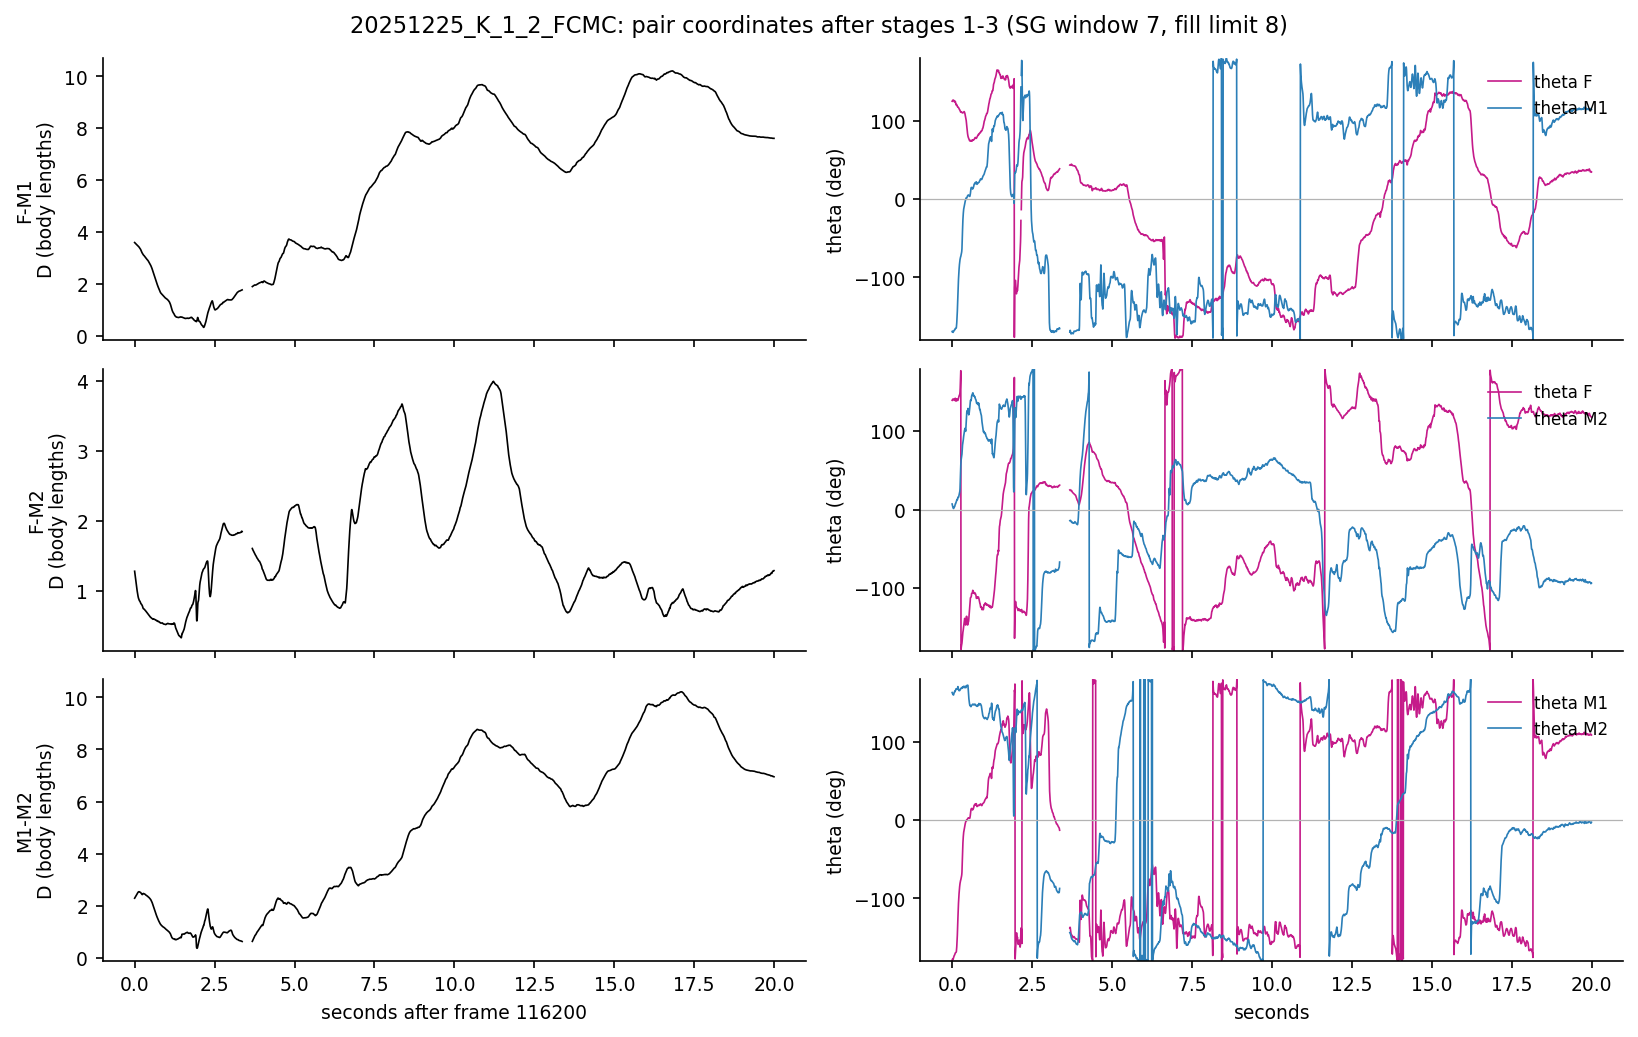

figure: \\bucket.oist.jp\bucket\StephensU\medaka\runs\behavior_features\microstate_infomap\S4_01_pair_coordinates_example_20s.png


In [3]:
EX = DEV[1]
P = PROC[EX]
fps = P["fps"]; W = int(20 * fps)
score = []
for s0 in range(0, len(P["seg"]) - W, W):
    d = P["pairs"]["F-M1"][0][s0:s0 + W]
    score.append((np.isfinite(d).mean() >= 0.9, np.nanstd(d) if np.isfinite(d).any() else 0, s0))
s0 = max((s for s in score if s[0]), default=max(score))[2]
t = np.arange(W) / fps
fig, axes = plt.subplots(3, 2, figsize=(11, 7), sharex=True)
for row, pair in enumerate(M.PAIR_NAMES):
    D, ta, tb = M.pair_units(P, pair, D_UNIT)
    a, b = pair.split("-")
    axes[row, 0].plot(t, D[s0:s0 + W], color="k", lw=0.8); axes[row, 0].set_ylabel(f"{pair}\nD (body lengths)")
    axes[row, 1].plot(t, np.degrees(ta[s0:s0 + W]), color="#c51b8a", lw=0.8, label=f"theta {a}")
    axes[row, 1].plot(t, np.degrees(tb[s0:s0 + W]), color="#2c7fb8", lw=0.8, label=f"theta {b}")
    axes[row, 1].axhline(0, color="0.7", lw=0.6); axes[row, 1].set_ylim(-180, 180); axes[row, 1].set_ylabel("theta (deg)")
    axes[row, 1].legend(frameon=False, loc="upper right", fontsize=8)
axes[-1, 0].set_xlabel(f"seconds after frame {P['frames'][s0]}"); axes[-1, 1].set_xlabel("seconds")
fig.suptitle(f"{EX}: pair coordinates after stages 1-3 (SG window {PARAMS['stage3']['window']}, fill limit {PARAMS['stage2']['fill_limit']})")
fig.tight_layout()
show(fig, 4, 1, "pair_coordinates_example_20s")

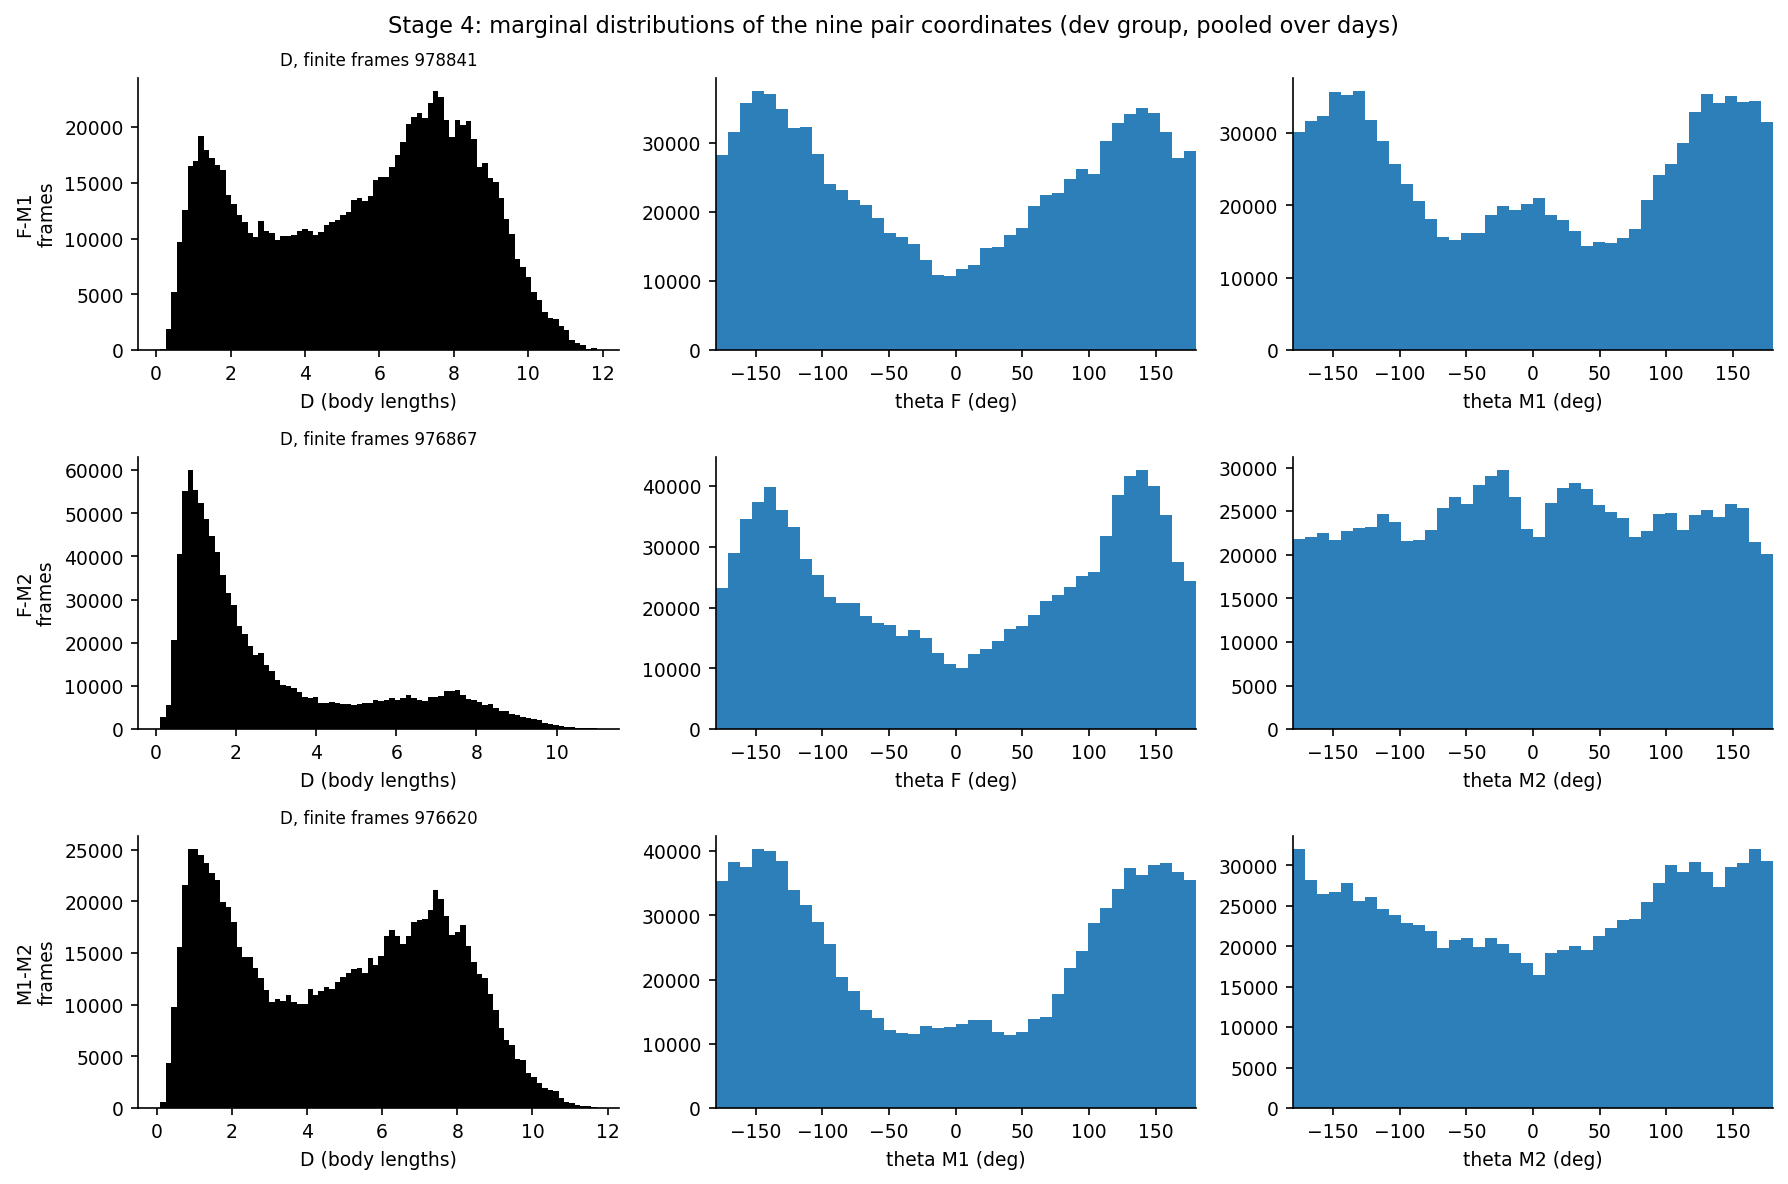

figure: \\bucket.oist.jp\bucket\StephensU\medaka\runs\behavior_features\microstate_infomap\S4_02_pair_coordinate_distributions.png


In [4]:
POOL = {pair: [np.concatenate(x) for x in zip(*[M.pair_units(P, pair, D_UNIT) for P in PROC.values()])] for pair in M.PAIR_NAMES}
fig, axes = plt.subplots(3, 3, figsize=(12, 8))
for row, pair in enumerate(M.PAIR_NAMES):
    D, ta, tb = POOL[pair]
    a, b = pair.split("-")
    axes[row, 0].hist(D[np.isfinite(D)], bins=80, color="k"); axes[row, 0].set_xlabel("D (body lengths)"); axes[row, 0].set_ylabel(f"{pair}\nframes")
    for col, (v, nm) in enumerate(((ta, a), (tb, b)), start=1):
        axes[row, col].hist(np.degrees(v[np.isfinite(v)]), bins=np.linspace(-180, 180, 41), color="#2c7fb8")
        axes[row, col].set_xlabel(f"theta {nm} (deg)"); axes[row, col].set_xlim(-180, 180)
    axes[row, 0].set_title(f"D, finite frames {np.isfinite(D).sum()}", fontsize=8)
fig.suptitle("Stage 4: marginal distributions of the nine pair coordinates (dev group, pooled over days)")
fig.tight_layout()
show(fig, 4, 2, "pair_coordinate_distributions")

**垂直运动检查**：左图是每条鱼的头部俯仰角（胸鳍→嘴 向量与水平面的夹角）；右图是每一对鱼胸鳍的垂直分离占 3D 距离的比例。俯仰角大或垂直分离占比大，说明只用 XY 角会丢掉信息。

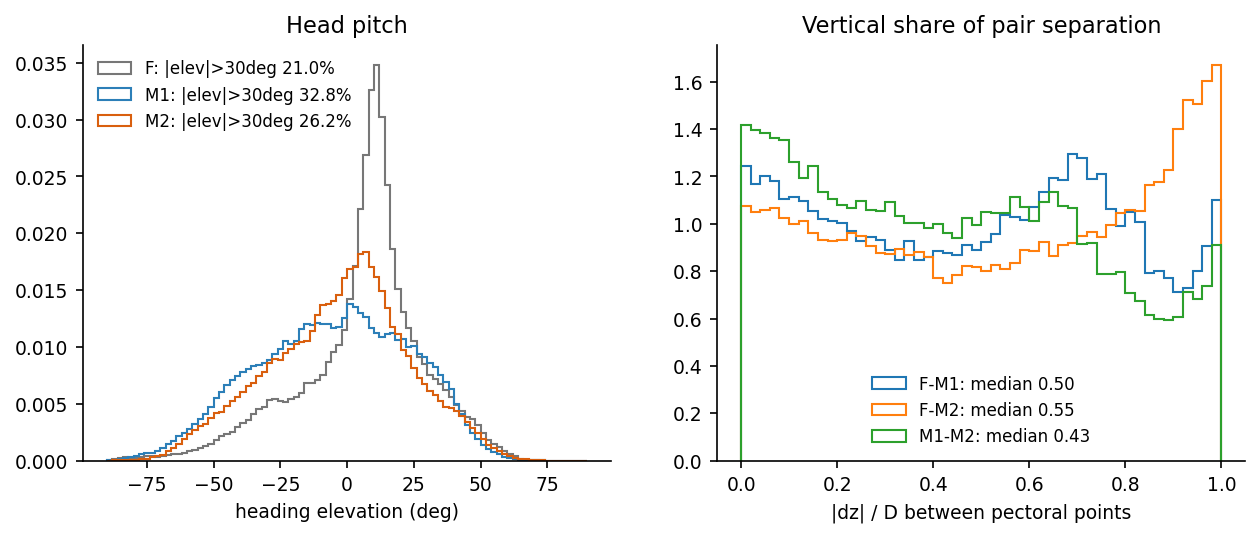

figure: \\bucket.oist.jp\bucket\StephensU\medaka\runs\behavior_features\microstate_infomap\S4_03_vertical_motion_check.png
share of distance-valid frames with an empty theta_a (near-vertical or overlapping in XY): {'F-M1': 0.0018, 'F-M2': 0.0026, 'M1-M2': 0.0015}


In [5]:
elev = {n: [] for n in M.NAMES}
vfrac = {p: [] for p in M.PAIR_NAMES}
for P in PROC.values():
    nodes = P["nodes"]
    h = nodes[:, :, M.MOUTH] - nodes[:, :, M.PECT]
    ang = np.degrees(np.arcsin(np.clip(h[..., 2] / np.linalg.norm(h, axis=-1), -1, 1)))
    for i, n in enumerate(M.NAMES):
        elev[n].append(ang[:, i][np.isfinite(ang[:, i])])
    for a, b in M.PAIRS:
        d = nodes[:, M.NAMES.index(b), M.PECT] - nodes[:, M.NAMES.index(a), M.PECT]
        v = np.abs(d[:, 2]) / np.linalg.norm(d, axis=-1)
        vfrac[f"{a}-{b}"].append(v[np.isfinite(v)])
elev = {k: np.concatenate(v) for k, v in elev.items()}; vfrac = {k: np.concatenate(v) for k, v in vfrac.items()}
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
for n, c in zip(M.NAMES, ("#777777", "#2c7fb8", "#d95f0e")):
    ax[0].hist(elev[n], bins=np.linspace(-90, 90, 91), histtype="step", density=True, color=c, label=f"{n}: |elev|>30deg {np.mean(np.abs(elev[n]) > 30):.1%}")
ax[0].set_xlabel("heading elevation (deg)"); ax[0].legend(frameon=False, fontsize=8); ax[0].set_title("Head pitch")
for p in M.PAIR_NAMES:
    ax[1].hist(vfrac[p], bins=np.linspace(0, 1, 51), histtype="step", density=True, label=f"{p}: median {np.median(vfrac[p]):.2f}")
ax[1].set_xlabel("|dz| / D between pectoral points"); ax[1].legend(frameon=False, fontsize=8); ax[1].set_title("Vertical share of pair separation")
show(fig, 4, 3, "vertical_motion_check")
ang_nan = {p: float(np.mean(~np.isfinite(POOL[p][1]) & np.isfinite(POOL[p][0]))) for p in M.PAIR_NAMES}
print("share of distance-valid frames with an empty theta_a (near-vertical or overlapping in XY):", {k: round(v, 4) for k, v in ang_nan.items()})

## 阶段 5：分格

D 取 `[0, D_MAX)`，θ 取 `[-π, π)`，每个变量 n 格，共 n³ 个状态（论文 n = 20 → 8000）。θ 是环形，−π 和 π 是同一方向；Infomap 只看转移不看相邻，所以聚类自动处理，只在画图时要注意。

**D 上限**：看三种配对的距离分布，取合并分布的 `D_MAX_Q` 分位数（起点 0.95），按 0.25 个体长取整。超过 D_MAX 的帧**不进状态**（记为缺失，比例在下面报告），因为论文没说明超出怎么处理。
**格数**：固定 D_MAX 后试 n = 8, 10, 15, 20，在参考 τ（`TAU_REF = 12` 帧，约论文突变位置）下看三个量：被占用的格子占比、每个被占用格子的中位帧数、**落在“出发转移 ≥ `M_MIN` 次”的格子里的帧占比**（M_MIN = 30 是经验起点）。
选满足 `frac_frames_ok ≥ FRAC_OK`（三种配对都满足）的最大 n。

**这条判据对这批数据不起筛选作用**（见 S5_02：n = 8…20 全部通过）。原因是 θ 分布很宽，转移散在很多格子里，“出发转移 ≥ 30 次”很容易满足，但并不保证转移矩阵够稠密到能稳定聚类。
真正的检验是 ms03 里 Infomap 在不同种子下的稳定性（NMI）；如果那里报不稳定，把下面的 `N_BINS_OVERRIDE` 改小，重跑 ms02 → ms03。

        F-M1   F-M2  M1-M2
p50     6.10   1.85   5.02
p90     9.06   7.25   8.47
p95     9.62   8.11   9.07
p99    10.63   9.42  10.16
p99.9  11.33  10.43  11.06

D_MAX = 9.25 body lengths = 230 mm (mean BL 24.8 mm)
share of valid frames beyond D_MAX: {'F-M1': 0.0804, 'F-M2': 0.0131, 'M1-M2': 0.0396}


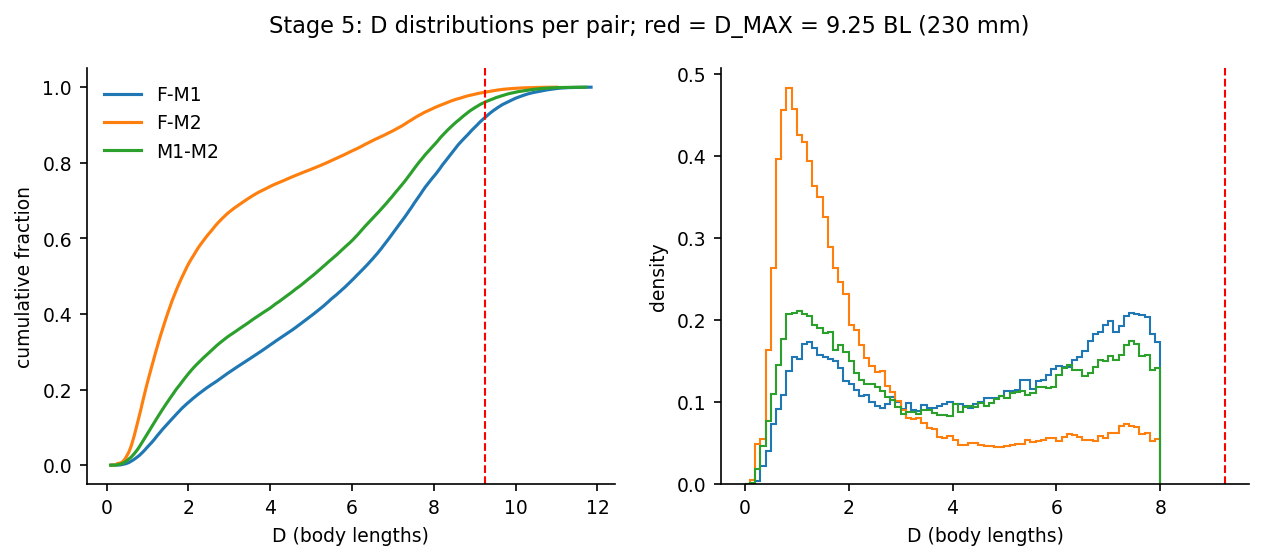

figure: \\bucket.oist.jp\bucket\StephensU\medaka\runs\behavior_features\microstate_infomap\S5_01_D_max_choice.png


In [6]:
DMAX_Q = 0.95
allD = np.concatenate([POOL[p][0][np.isfinite(POOL[p][0])] for p in M.PAIR_NAMES])
q_tab = pd.DataFrame({p: [np.nanquantile(POOL[p][0], q) for q in (0.5, 0.9, 0.95, 0.99, 0.999)] for p in M.PAIR_NAMES},
                     index=["p50", "p90", "p95", "p99", "p99.9"])
DMAX = float(np.round(np.quantile(allD, DMAX_Q) / 0.25) * 0.25)
bl_mean = np.mean([P["body_length_mm"].mean() for P in PROC.values()])
print(q_tab.round(2).to_string()); print(f"\nD_MAX = {DMAX} body lengths = {DMAX * bl_mean:.0f} mm (mean BL {bl_mean:.1f} mm)")
print("share of valid frames beyond D_MAX:", {p: round(float(np.mean(POOL[p][0][np.isfinite(POOL[p][0])] >= DMAX)), 4) for p in M.PAIR_NAMES})

fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
for p in M.PAIR_NAMES:
    x = np.sort(POOL[p][0][np.isfinite(POOL[p][0])])
    ax[0].plot(x, np.arange(1, len(x) + 1) / len(x), label=p)
    ax[1].hist(x, bins=np.linspace(0, 8, 81), histtype="step", density=True, label=p)
for a_ in ax: a_.axvline(DMAX, color="r", ls="--", lw=1)
ax[0].set_xlabel("D (body lengths)"); ax[0].set_ylabel("cumulative fraction"); ax[0].legend(frameon=False)
ax[1].set_xlabel("D (body lengths)"); ax[1].set_ylabel("density")
fig.suptitle(f"Stage 5: D distributions per pair; red = D_MAX = {DMAX} BL ({DMAX * bl_mean:.0f} mm)")
show(fig, 5, 1, "D_max_choice")

 n  pair  states  occupied_frac  median_frames_per_occupied  frac_frames_ok  valid_frames  pairs_at_tau_ref
 8  F-M1     512          1.000                      1247.0           1.000        897455            887443
 8  F-M2     512          1.000                      1153.5           1.000        961838            954565
 8 M1-M2     512          0.994                      1590.0           1.000        936228            927585
10  F-M1    1000          0.997                       635.0           1.000        897455            887443
10  F-M2    1000          0.994                       565.0           1.000        961838            954565
10 M1-M2    1000          0.989                       805.0           1.000        936228            927585
15  F-M1    3375          0.983                       182.0           0.994        897455            887443
15  F-M2    3375          0.971                       155.0           0.993        961838            954565
15 M1-M2    3375          0.

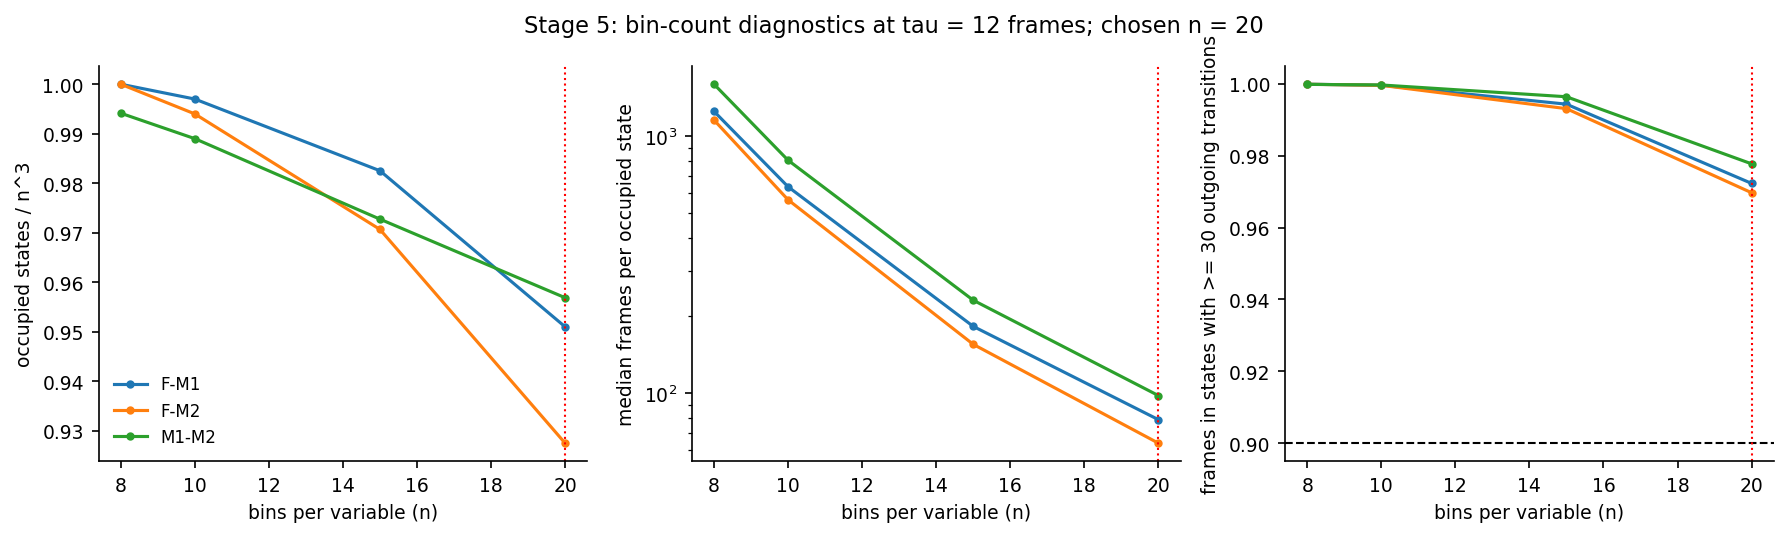

figure: \\bucket.oist.jp\bucket\StephensU\medaka\runs\behavior_features\microstate_infomap\S5_02_bin_count_diagnostics.png


In [7]:
TAU_REF, M_MIN, FRAC_OK = 12, 30, 0.90
NS = (8, 10, 15, 20)
rows = []
for n in NS:
    for pair in M.PAIR_NAMES:
        items = [(M.bin_states(*M.pair_units(P, pair, D_UNIT), n, DMAX), P["seg"]) for P in PROC.values()]
        cnt, npair = M.pooled_counts(items, TAU_REF, n ** 3)
        out_deg = np.asarray(cnt.sum(axis=1)).ravel()
        fr = M.state_frame_counts(items, n ** 3)
        occ = fr > 0
        rows.append({"n": n, "pair": pair, "states": n ** 3, "occupied_frac": occ.mean(), "median_frames_per_occupied": float(np.median(fr[occ])),
                     "frac_frames_ok": float(fr[out_deg >= M_MIN].sum() / fr.sum()), "valid_frames": int(fr.sum()), "pairs_at_tau_ref": npair})
diag = pd.DataFrame(rows)
diag.to_csv(OUT / "S5_bin_count_diagnostics.csv", index=False)
print(diag.round(3).to_string(index=False))
good = [n for n in NS if (diag.loc[diag["n"] == n, "frac_frames_ok"] >= FRAC_OK).all()]
N_BINS = max(good) if good else min(NS)
N_BINS_OVERRIDE = None      # e.g. 10 after ms03 reports unstable clusterings at the chosen n
if N_BINS_OVERRIDE:
    N_BINS = int(N_BINS_OVERRIDE)
print("n meeting frac_frames_ok >=", FRAC_OK, "for all pairs:", good, "-> N_BINS =", N_BINS)

fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
for pair in M.PAIR_NAMES:
    d = diag[diag["pair"] == pair]
    axes[0].plot(d["n"], d["occupied_frac"], "-o", ms=3, label=pair)
    axes[1].plot(d["n"], d["median_frames_per_occupied"], "-o", ms=3, label=pair)
    axes[2].plot(d["n"], d["frac_frames_ok"], "-o", ms=3, label=pair)
axes[0].set_ylabel("occupied states / n^3"); axes[1].set_ylabel("median frames per occupied state"); axes[1].set_yscale("log")
axes[2].set_ylabel(f"frames in states with >= {M_MIN} outgoing transitions"); axes[2].axhline(FRAC_OK, color="k", ls="--", lw=1)
for a_ in axes: a_.set_xlabel("bins per variable (n)"); a_.axvline(N_BINS, color="r", ls=":", lw=1)
axes[0].legend(frameon=False, fontsize=8)
fig.suptitle(f"Stage 5: bin-count diagnostics at tau = {TAU_REF} frames; chosen n = {N_BINS}")
fig.tight_layout()
show(fig, 5, 2, "bin_count_diagnostics")

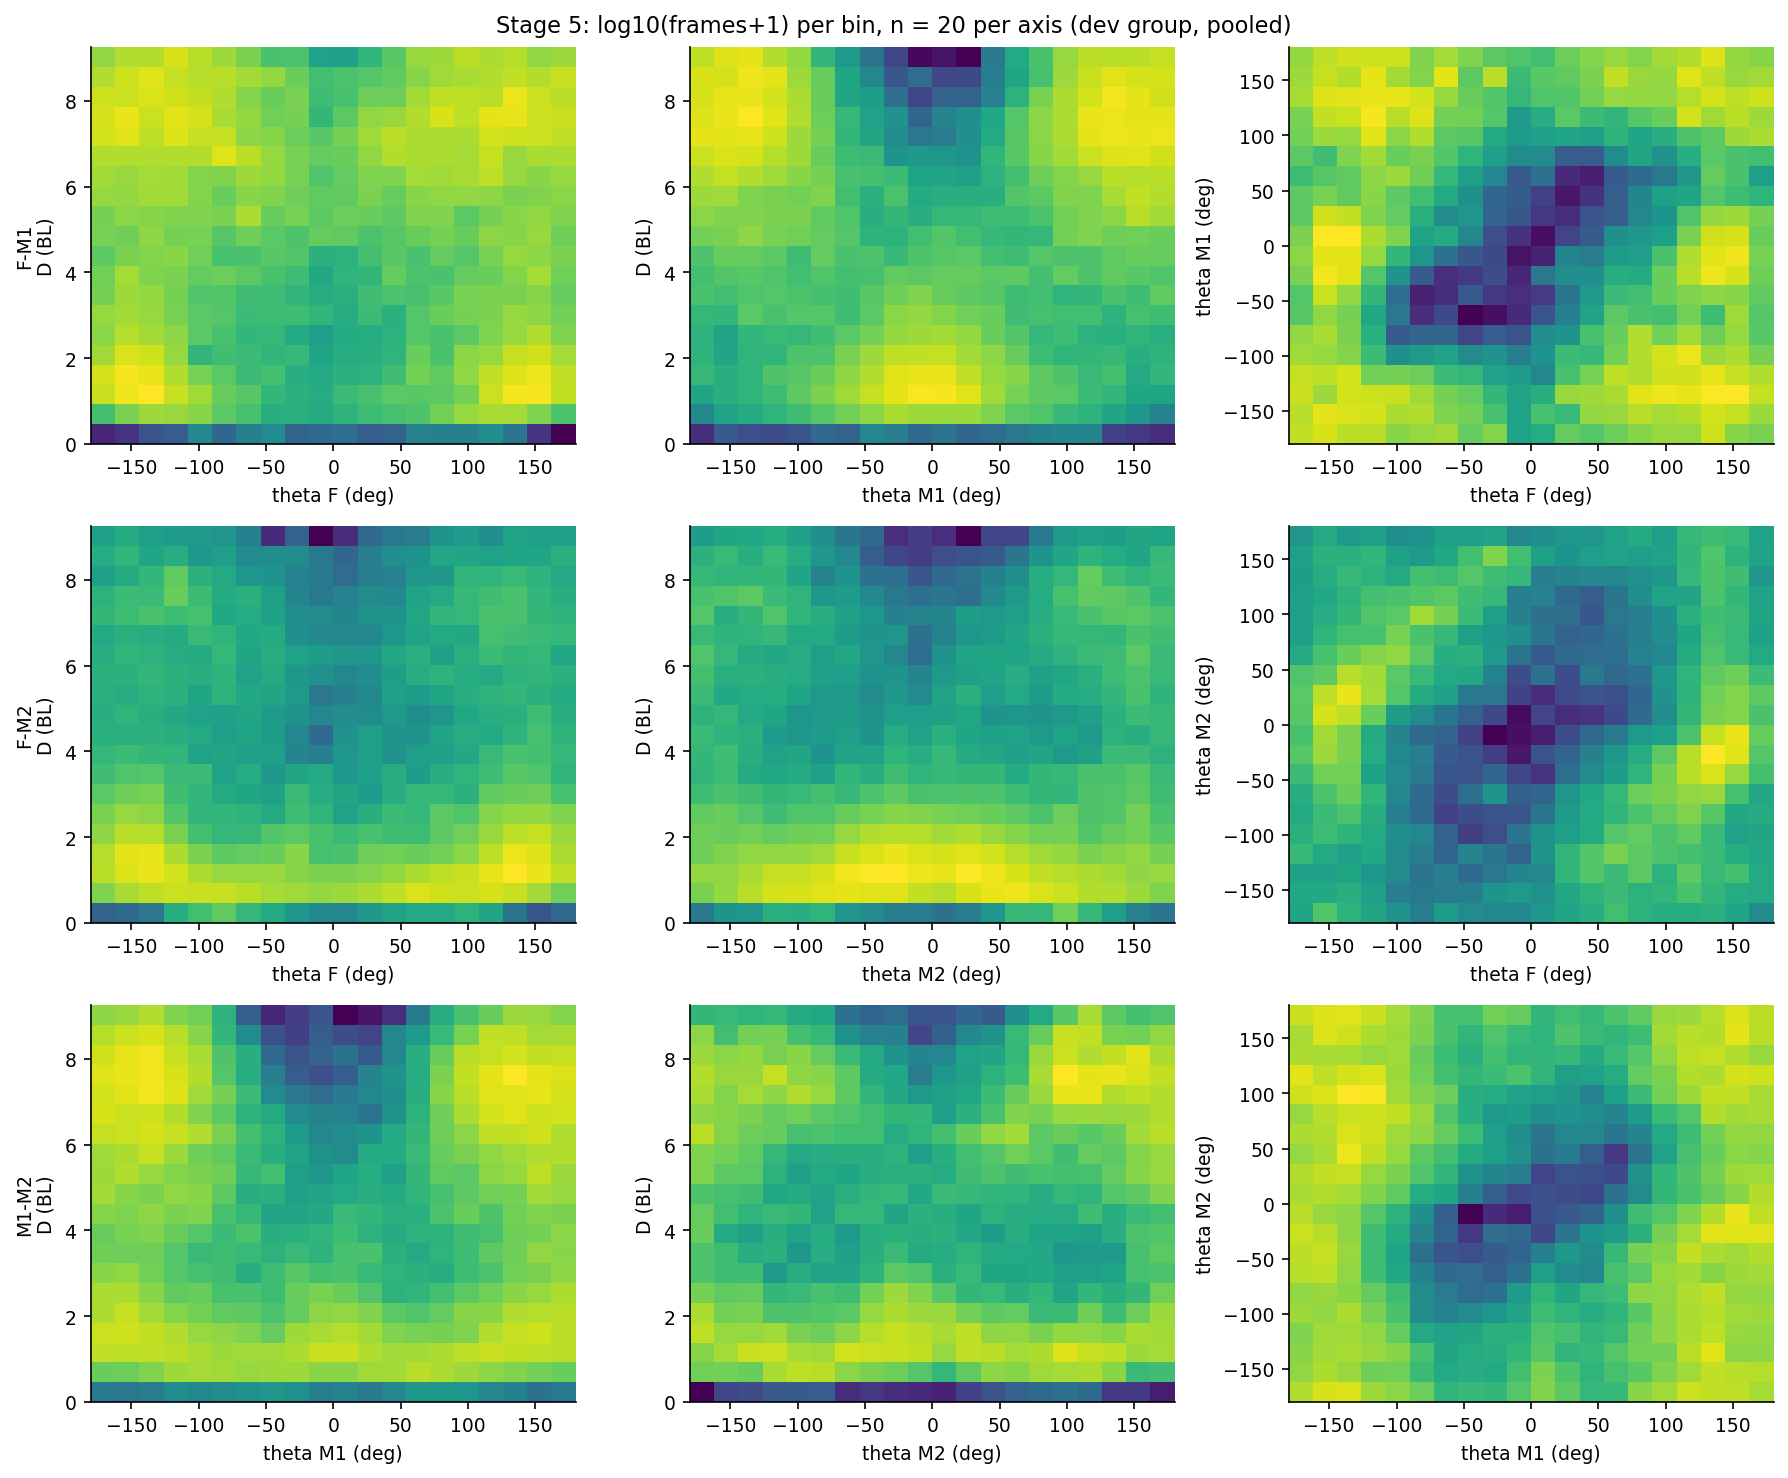

figure: \\bucket.oist.jp\bucket\StephensU\medaka\runs\behavior_features\microstate_infomap\S5_03_state_occupancy_marginals.png
{'n_bins': 20, 'dmax_bl': 9.25, 'dmax_quantile': 0.95, 'tau_ref': 12, 'm_min': 30, 'frac_ok': 0.9, 'candidates': [8, 10, 15, 20], 'rule': 'largest n with >=frac_ok of frames in states with >=m_min outgoing transitions, all three pairs'}


In [8]:
fig, axes = plt.subplots(3, 3, figsize=(12, 10))
for row, pair in enumerate(M.PAIR_NAMES):
    D, ta, tb = POOL[pair]
    a, b = pair.split("-")
    ok = np.isfinite(D) & np.isfinite(ta) & np.isfinite(tb) & (D < DMAX)
    edges_t = np.linspace(-180, 180, N_BINS + 1); edges_d = np.linspace(0, DMAX, N_BINS + 1)
    for col, (x, y, ex, ey, xl, yl) in enumerate((
            (np.degrees(ta[ok]), D[ok], edges_t, edges_d, f"theta {a} (deg)", "D (BL)"),
            (np.degrees(tb[ok]), D[ok], edges_t, edges_d, f"theta {b} (deg)", "D (BL)"),
            (np.degrees(ta[ok]), np.degrees(tb[ok]), edges_t, edges_t, f"theta {a} (deg)", f"theta {b} (deg)"))):
        H, _, _ = np.histogram2d(x, y, bins=[ex, ey])
        im = axes[row, col].pcolormesh(ex, ey, np.log10(H.T + 1), cmap="viridis")
        axes[row, col].set_xlabel(xl); axes[row, col].set_ylabel(yl if col else f"{pair}\n{yl}")
fig.suptitle(f"Stage 5: log10(frames+1) per bin, n = {N_BINS} per axis (dev group, pooled)")
fig.tight_layout()
show(fig, 5, 3, "state_occupancy_marginals")
M.update_params("stage4", {"d_unit": D_UNIT, "pairs": list(M.PAIR_NAMES), "min_xy_mm": M.MIN_XY_MM,
                           "theta_reference": "horizontal line pectoral(a)->pectoral(b); 0 = facing the other fish (to be checked against Fig 2c / SM Fig S4)"})
M.update_params("stage5", {"n_bins": int(N_BINS), "dmax_bl": DMAX, "dmax_quantile": DMAX_Q, "tau_ref": TAU_REF, "m_min": M_MIN,
                           "frac_ok": FRAC_OK, "candidates": list(NS), "rule": "largest n with >=frac_ok of frames in states with >=m_min outgoing transitions, all three pairs"})
print(M.load_params()["stage5"])